In [1]:
import torch
from torch import nn
from d2l import torch as d2l


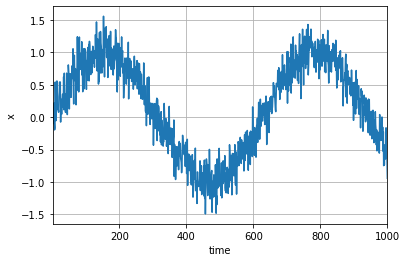

In [2]:
T = 1000
time = torch.arange(1, T + 1, dtype=torch.float32)
x = torch.sin(0.01 * time) + torch.normal(0, 0.2, (T,))
d2l.plot([time], [x], 'time', 'x', xlim=[1, 1000], figsize=(6, 3))



In [3]:
tau = 4
features = torch.zeros((T - tau, tau))
for i in range(tau):
    features[:, i] = x[i: T - tau + i]
print(features.shape)   

torch.Size([996, 4])


In [4]:
labels = x[tau:].reshape((-1, 1))
batch_size, n_train = 16, 600
# 只有前n_train个样本用于训练
train_iter = d2l.load_array((features[:n_train], labels[:n_train]),
                            batch_size, is_train=True)
                            


In [5]:
# 初始化网络权重的函数
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)

In [6]:
# 一个简单的多层感知机
def get_net():
    net = nn.Sequential(nn.Linear(4, 10),
                        nn.ReLU(),
                        nn.Linear(10, 1))
    net.apply(init_weights)
    return net
    

# 平方损失。注意：MSELoss计算平方误差时不带系数1/2
loss = nn.MSELoss(reduction='none')

In [11]:
def train(net, train_iter, loss, epochs, lr):
    trainer = torch.optim.Adam(net.parameters(), lr)
    for epoch in range(epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.sum().backward()
            trainer.step()
        print(f'epoch {epoch + 1}, '
              f'loss: {d2l.evaluate_loss(net, train_iter, loss):f}')

net = get_net()
train(net, train_iter, loss, 5, 0.01)

epoch 1, loss: 0.062178
epoch 2, loss: 0.059913
epoch 3, loss: 0.058673
epoch 4, loss: 0.057696
epoch 5, loss: 0.057198


NameError: name 'onestep_preds' is not defined

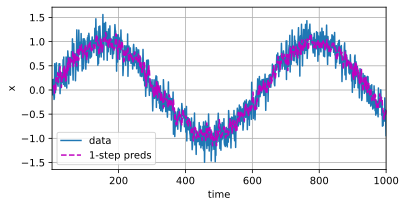

In [13]:
onestep_preds = net(features)
d2l.plot([time, time[tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy()], 'time',
         'x', legend=['data', '1-step preds'], xlim=[1, 1000],
         figsize=(6, 3))

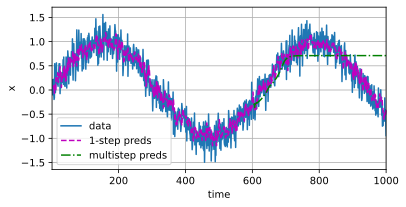

In [14]:
multistep_preds = torch.zeros(T)
multistep_preds[: n_train + tau] = x[: n_train + tau]
for i in range(n_train + tau, T):
    multistep_preds[i] = net(
        multistep_preds[i - tau:i].reshape((1, -1)))

d2l.plot([time, time[tau:], time[n_train + tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy(),
          multistep_preds[n_train + tau:].detach().numpy()], 'time',
         'x', legend=['data', '1-step preds', 'multistep preds'],
         xlim=[1, 1000], figsize=(6, 3))

In [17]:
multistep_preds

tensor([ 0.2124, -0.1007,  0.0536, -0.0669,  0.2185, -0.0753, -0.1956, -0.1627,
         0.5433,  0.2676, -0.0539,  0.0718,  0.2458,  0.5600,  0.1755,  0.1930,
         0.1174,  0.1244,  0.0776,  0.3188,  0.3874,  0.5421,  0.3643,  0.5433,
        -0.0749,  0.1962,  0.2689,  0.0466,  0.2853,  0.2889,  0.3564,  0.2214,
         0.1524,  0.6233,  0.1145,  0.6800,  0.2547,  0.3596,  0.0838,  0.0745,
         0.2073,  0.2736,  0.6812,  0.5687,  0.0406,  0.6562,  0.3060,  0.8075,
         0.7050,  0.6257,  0.1281,  0.6218,  0.6732,  0.6703,  0.6523,  0.3069,
         0.5693,  0.5925,  0.7929,  0.6803,  0.6086,  1.0570,  0.4485,  0.2049,
         0.7919,  0.9570,  0.5982,  0.5637,  0.7505,  0.7331,  0.1916,  0.4465,
         0.5399,  0.7470,  1.2422,  0.9178,  0.4156,  0.8428,  0.3909,  0.8512,
         1.2378,  0.8487,  0.7984,  0.7383,  0.9864,  0.8250,  0.8074,  1.1662,
         0.6514,  0.7763,  0.3938,  0.7465,  0.9607,  1.0568,  0.4387,  0.7928,
         1.0597,  0.8581,  1.0306,  0.98

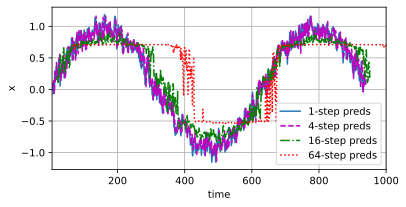

In [ ]:
max_steps = 64

features = torch.zeros((T - tau - max_steps + 1, tau + max_steps))
# (933, 68)
# 列i（i<tau）是来自x的观测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau):
    features[:, i] = x[i: i + T - tau - max_steps + 1]
    
# 列i（i>=tau）是来自（i-tau+1）步的预测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau, tau + max_steps):
    features[:, i] = net(features[:, i - tau:i]).reshape(-1)

steps = (1, 4, 16, 64)
d2l.plot([time[tau + i - 1: T - max_steps + i] for i in steps],
         [features[:, (tau + i - 1)].detach().numpy() for i in steps], 'time', 'x',
         legend=[f'{i}-step preds' for i in steps], xlim=[5, 1000],
         figsize=(6, 3))

In [28]:
features[10]


tensor([-0.0539,  0.0718,  0.2458,  0.5600,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000])